<center><img src='https://drive.google.com/uc?id=1_utx_ZGclmCwNttSe40kYA6VHzNocdET' height="60"></center>

AI TECH - Akademia Innowacyjnych Zastosowań Technologii Cyfrowych. Program Operacyjny Polska Cyfrowa na lata 2014-2020
<hr>

<center><img src='https://drive.google.com/uc?id=1BXZ0u3562N_MqCLcekI-Ens77Kk4LpPm'></center>

<center>
Projekt współfinansowany ze środków Unii Europejskiej w ramach Europejskiego Funduszu Rozwoju Regionalnego
Program Operacyjny Polska Cyfrowa na lata 2014-2020,
Oś Priorytetowa nr 3 "Cyfrowe kompetencje społeczeństwa" Działanie  nr 3.2 "Innowacyjne rozwiązania na rzecz aktywizacji cyfrowej"
Tytuł projektu:  „Akademia Innowacyjnych Zastosowań Technologii Cyfrowych (AI Tech)”
    </center>

This exercise covers two aspects:
* In tasks 1-6 you will implement mechanisms that allow training deeper models. After doing each of the tasks you can look at the plots and check how your changes impact gradients of network layers.
* In task 7 you will implement a convnet using [conv2d](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) and try to reach 99% accuracy on MNIST.

For this notebook, running on CPU is sufficient: tasks 1–5. run under a minute, 6. under two minutes, and 7. up to 5 minutes.

Tasks:
1. Check that the given implementation reaches 95% test accuracy for
   the architecture `input-64-64-10` in 8 epochs.
2. Modify `Linear.reset_parameters()` to improve initialization and
   check that the network learns much faster and reaches over 97% test accuracy.
   A good basic initialization scheme is so-called *Glorot initialization*.
   For a linear layer with $n_{in}$ and  $n_{out}$ input and output features,
   it samples each weight from a normal distribution with $0$ mean and a standard deviation of $\sqrt{\frac{2}{n_{in}+n_{out}}}$.  
   Check how that changes the distribution of gradients at the first epoch.
3. Check, that with proper initialization we can train the architecture
   `input-64-64-64-64-64-64-64-10` (seven hidden layers of `64`), for e.g. 3 epochs,
   while with the original, bad initialization, it does not even get off the ground.
4. Implement Dropout as a PyTorch module (without using torch.nn.Dropout).
   Use `p=0.25` as the zeroing probability.
   Use Dropout after activations of each layer, except the last.
5. Check that with 10 hidden layers (64 units each), even with proper initialization,
   but with dropout added, the network has a hard time to start learning.
6. Implement batch normalization (without using torch.nn.BatchNorm).
    * compute batch mean and variance
    * add new variables beta and gamma
    * check that the network learns even for 10 hidden layers.
    * check how gradients change in comparison to network without batch norm.
   
   In pseudo-code:
    ```
		if training:
		    var, mean = torch.var_mean(x, dim=/batch/)
		    update running_mean, running_var
		else:
			mean, var = running_mean, running_var
		x = (x - mean) / sqrt(var + eps)
		return x * gamma + beta
    ```

7. Design and implement a simple convolutional network and achieve 99% test accuracy (in up to 10 epochs, 5 should be enough). The architecture is up to you, but even a few convolutional layers should be enough.
You may use `torch.nn.Conv2d, BatchNorm2d, MaxPool2d, ReLU, Dropout2d, Linear, Flatten, BatchNorm1d`.
Don't make it too generic, just try a few fixed layers.

In [15]:
import math
import sys

import numpy as np
import PIL.Image
import plotly.express as px
import plotly.graph_objects as go
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from plotly.subplots import make_subplots
from torch import Tensor
from torch.nn import init

if 'google.colab' in sys.modules:
    from google.colab import output
    output.enable_custom_widget_manager()

In [16]:
# @title Visualize gradients

class GradientVisualizer:
    def __init__(self, net: nn.Module, num_epochs: int) -> None:
        self.num_epochs = num_epochs
        self.linear_layers = self.get_linear_layers(net)

        self.grad_to_weight_fig = None
        self.grads_in_layers_fig = None
        self.grads_at_epochs_fig = None
        self.init_figures()

    @staticmethod
    def get_linear_layers(net):
        linear_layers = []
        for field in net.modules():
            if isinstance(field, nn.Linear | Linear):
                linear_layers.append(field)
        assert linear_layers, "No linear layers found. Forgot to use Sequential or ModuleList?"
        return linear_layers

    def get_epochs_for_one_layer(self):
        """
        We want to show gradient distributions from up to 7 selected epochs
        for one linear layer.
        """
        if self.num_epochs < 7:
            return list(range(self.num_epochs))
        else:
            return torch.linspace(0, self.num_epochs - 1, 7).int().tolist()

    def get_three_epochs(self):
        """
        We want to show gradients distributions from all layers at each of
        three epochs: first, middle and last.
        """
        return [0, self.num_epochs // 2, self.num_epochs - 1]

    def rgb_to_rgba(self, rgb_color, epoch):
        """
        Value of epoch parameter determines how transparent color should be
        in comparison to others.
        Colors for earlier epochs should be more transparent/less visible.
        """
        return f'rgba{rgb_color[3:-1]},{0.6 * (epoch + 1) / self.num_epochs + 0.15})'

    def init_figures(self):
        # Initialize figure with gradient to weight ratio plot
        fig = go.Figure()
        fig.update_layout(
            title='Gradient stddev to weight stddev ratio', title_x=0.5,
            xaxis_title='Epoch',
            yaxis_title='Gradient to weight ratio (log scale)',
            height=400, width=1500, margin=dict(b=10, t=60)
        )
        fig.update_yaxes(type='log')
        for i in range(len(self.linear_layers)):
            fig.add_trace(go.Scatter(
                x=[], y=[],
                mode='lines+markers', name=f'Linear layer {i}'
            ))

        self.grad_to_weight_fig = go.FigureWidget(fig)
        display(self.grad_to_weight_fig)

        # Initialize figure visualizing gradient distributions in layers
        chosen_layers = [0, len(self.linear_layers) // 2, len(self.linear_layers) - 1]
        num_rows = (len(chosen_layers) - 1) // 3 + 1
        fig = make_subplots(
            rows=num_rows, cols=3,
            subplot_titles=[f'Linear layer {i}' for i in chosen_layers],
            vertical_spacing=0.2 / num_rows
        )
        fig.update_layout(
            title='Gradient distributions by epoch (for three chosen layers)', title_x=0.5,
            height=num_rows * 400, width=1500, margin=dict(b=10, t=60)
        )

        colors, _ = px.colors.convert_colors_to_same_type(2 * px.colors.qualitative.Plotly)
        for i, layer_num in enumerate(chosen_layers):
            row = i // 3 + 1
            col = i % 3 + 1
            fig.update_xaxes(
                title_text='Gradient value', range=(-0.1, 0.1), row=row, col=col
            )
            fig.update_yaxes(
                title_text='Density (log scale)', type='log', row=row, col=col
            )

            # Create empty traces and update them later with actual gradient distributions.
            # Unfortunately, we cannot add new traces dynamically because Colab has problem
            # with widgets from plotly (traces added dynamically are rendered twice).
            for epoch in self.get_epochs_for_one_layer():
                fig.add_trace(
                    go.Scatter(
                        mode='lines', name=f'Epoch {epoch + 1}',
                        line=dict(color=self.rgb_to_rgba(colors[layer_num], epoch)),
                        legendgroup=layer_num
                    ),
                    row=row, col=col
                )

        self.grads_in_layers_fig = go.FigureWidget(fig)
        display(self.grads_in_layers_fig)

        # Initialize figure comparing gradient distributions between layers at the
        # first, middle and last epoch
        selected_epochs_indices = self.get_three_epochs()
        fig = make_subplots(
            rows=1, cols=3,
            subplot_titles=[f'Epoch {epoch + 1}' for epoch in selected_epochs_indices]
        )
        fig.update_layout(
            title='Gradient distributions by layers (for three chosen epochs)', title_x=0.5,
            height=400, width=1500, margin=dict(b=10, t=60)
        )

        for col, epoch in enumerate(selected_epochs_indices, 1):
            fig.update_yaxes(title_text='Density (log scale)', type='log', row=1, col=col)
            fig.update_xaxes(
                title_text='Gradient value',
                range=(-0.05, 0.05) if epoch != 0 else (-1, 1),
                row=1, col=col
            )

            # Create empty traces and update them later with actual gradient distributions.
            for layer_num in range(len(self.linear_layers)):
                fig.append_trace(
                    go.Scatter(
                        mode='lines', name=f'Linear layer {layer_num}',
                        line=dict(color=colors[layer_num]), showlegend=(col == 1)
                    ),
                    row=1, col=col
                )

        self.grads_at_epochs_fig = go.FigureWidget(fig)
        display(self.grads_at_epochs_fig)

    def visualize_gradients(self, lr, epoch, batch_idx):
        # It is enough to use gradients calculated for the first batch.
        if batch_idx != 0:
            return

        epoch_grads = []
        epoch_grad_to_weight_ratios = []
        for layer in self.linear_layers:
            epoch_grads.append(layer.weight.grad.flatten().detach())
            epoch_grad_to_weight_ratios.append(
                (lr * layer.weight.grad.std() / layer.weight.std()).item()
            )

        # Update figure with gradient to weight ratio plot
        assert self.grad_to_weight_fig is not None
        for i, grad_to_weight_ratio in enumerate(epoch_grad_to_weight_ratios):
            x = self.grad_to_weight_fig.data[i].x
            next_x_val = x[-1] + 1 if x else 1
            self.grad_to_weight_fig.data[i].x += (next_x_val, )
            self.grad_to_weight_fig.data[i].y += (grad_to_weight_ratio, )

        # Update figure visualizing gradient distributions in layers
        assert self.grads_in_layers_fig is not None
        chosen_layers = [0, len(self.linear_layers) // 2, len(self.linear_layers) - 1]
        selected_epochs = self.get_epochs_for_one_layer()
        if epoch in selected_epochs:
            epoch_idx = selected_epochs.index(epoch)
            for layer_num, layer_grad in enumerate(epoch_grads):
                try:
                    layer_id = chosen_layers.index(layer_num)
                except ValueError:
                    continue
                trace_idx = layer_id * len(selected_epochs) + epoch_idx
                try:
                    hy, hx = torch.histogram(layer_grad, bins=50, density=True)
                except RuntimeError:
                    continue
                hy = hy / max(hy) + 0.001
                self.grads_in_layers_fig.data[trace_idx].x = hx[:-1].tolist()
                self.grads_in_layers_fig.data[trace_idx].y = hy.tolist()


        # Update figure visualizing gradient distributions at epochs
        assert self.grads_at_epochs_fig is not None
        selected_epochs = self.get_three_epochs()
        if epoch in selected_epochs:
            epoch_idx = selected_epochs.index(epoch)
            for layer_num, layer_grad in enumerate(epoch_grads):
                trace_idx = epoch_idx * len(self.linear_layers) + layer_num
                try:
                    hy, hx = torch.histogram(layer_grad, bins=50, density=True)
                except RuntimeError:
                    continue
                hy = hy / max(hy) + 0.001
                self.grads_at_epochs_fig.data[trace_idx].x = hx[:-1].tolist()
                self.grads_at_epochs_fig.data[trace_idx].y = hy.tolist()

In [17]:
class Linear(nn.Module):
    def __init__(self, in_features: int, out_features: int, glorot_init: bool) -> None:
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.weight = nn.Parameter(Tensor(out_features, in_features))
        self.bias = nn.Parameter(Tensor(out_features))
        self.glorot_init = glorot_init
        self.reset_parameters()

    def reset_parameters(self) -> None:
        if self.glorot_init:
            # TODO Task 2.
            std = math.sqrt(2 / (self.in_features + self.out_features))
            self.weight.data.normal_(mean=0, std=std)
        else:
            self.weight.data.normal_(mean=0, std=0.25)
        init.zeros_(self.bias)

    def forward(self, x: Tensor) -> Tensor:
        """
        Input: shape (*B, in_features)
        Output: shape (*B, out_features)
        """
        r = x.matmul(self.weight.T)
        r += self.bias
        return r


class Net(nn.Module):
    def __init__(self, glorot_init: bool = False) -> None:
        super().__init__()
        self.fc1 = Linear(784, 64, glorot_init=glorot_init)
        self.fc2 = Linear(64, 64, glorot_init=glorot_init)
        self.fc3 = Linear(64, 10, glorot_init=glorot_init)

    def forward(self, x: Tensor) -> Tensor:
        """
        Input: shape (B, H=28, W=28)
        Output: shape (B, num_classes=10)
        """
        x = x.view(-1, 28 * 28)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [18]:
class MnistTrainer:
    def __init__(self, batch_size: int = 128) -> None:
        transform = transforms.Compose([transforms.ToTensor()])
        self.trainset = torchvision.datasets.MNIST(
            root='./data', download=True, train=True, transform=transform
        )
        self.trainloader = torch.utils.data.DataLoader(
            self.trainset, batch_size=batch_size, shuffle=True, num_workers=2
        )
        self.testset = torchvision.datasets.MNIST(
            root='./data', train=False, download=True, transform=transform
        )
        self.testloader = torch.utils.data.DataLoader(
            self.testset, batch_size=1000, shuffle=False, num_workers=2
        )

    def train(
        self,
        net: nn.Module,
        gradient_visualizer: GradientVisualizer | None = None,
        epochs: int = 20,
        lr: float = 0.05,
        momentum: float = 0.9
    ) -> None:
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.SGD(net.parameters(), lr=lr, momentum=momentum)
        log_freq = 100

        for epoch in range(epochs):
            net.train()
            running_loss = 0.0
            for i, data in enumerate(self.trainloader):
                inputs, labels = data
                optimizer.zero_grad()

                outputs = net(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                if gradient_visualizer is not None:
                    gradient_visualizer.visualize_gradients(lr, epoch, i)
                optimizer.step()

                running_loss += loss.item()
                if i % log_freq == log_freq - 1:
                    running_loss /= log_freq
                    print(f"epoch {epoch + 1:>5}, batch {i + 1:>5}, loss {running_loss:.3f}")
                    running_loss = 0.0
            self.test(net)

    def test(self, net: nn.Module) -> list[float]:
        net.eval()
        correct = 0
        total = 0
        all_gt_logits = []
        with torch.no_grad():
            for data in self.testloader:
                images, labels = data
                outputs = net(images)
                gt_logits = torch.gather(outputs, dim=1, index=labels.unsqueeze(-1))
                all_gt_logits.extend(float(logit.item()) for logit in gt_logits)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        print(f"Accuracy of the network on the {total} test images: {correct / total:.2%}")
        return all_gt_logits

    def show_worst_misclassified(self, net: nn.Module, k: int = 10) -> None:
        all_gt_logits = self.test(net)
        _, indices = torch.topk(-torch.tensor(all_gt_logits), k)
        imgs = []
        labels = []
        for i in indices:
            img, label = self.testset[int(i.item())]
            imgs.append(img)
            labels.append(label)
        image = PIL.Image.fromarray(
            torch.cat(imgs, dim=-1).mul(255).to(torch.uint8).permute(1, 2, 0).numpy().squeeze()
        )
        display(image.resize((5 * image.width, 5 * image.height), PIL.Image.Resampling.NEAREST))
        print(labels)

In [19]:
epochs = 20

net = Net()
gradient_visualizer = GradientVisualizer(net, epochs)

FigureWidget({
    'data': [{'mode': 'lines+markers',
              'name': 'Linear layer 0',
              'type': 'scatter',
              'uid': 'bd35c1ce-2392-46a7-8683-a8d27d006f15',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 1',
              'type': 'scatter',
              'uid': 'b18a66f3-8262-41c4-8c82-f492687169c4',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 2',
              'type': 'scatter',
              'uid': '93380078-c0b3-43e0-a852-6ae29b8cad76',
              'x': [],
              'y': []}],
    'layout': {'height': 400,
               'margin': {'b': 10, 't': 60},
               'template': '...',
               'title': {'text': 'Gradient stddev to weight stddev ratio', 'x': 0.5},
               'width': 1500,
               'xaxis': {'title': {'text': 'Epoch'}},
               'yaxis': {'title': {'text': 'G

FigureWidget({
    'data': [{'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.18)'},
              'mode': 'lines',
              'name': 'Epoch 1',
              'type': 'scatter',
              'uid': 'ccebee36-0b63-49d0-80ad-ac93b7c64a41',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.27)'},
              'mode': 'lines',
              'name': 'Epoch 4',
              'type': 'scatter',
              'uid': '7f92cead-15e2-4bf8-bfb6-34b786f204e5',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.36)'},
              'mode': 'lines',
              'name': 'Epoch 7',
              'type': 'scatter',
              'uid': 'af53fcf7-128a-41ef-96c4-cdaca04ec30f',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'

FigureWidget({
    'data': [{'line': {'color': 'rgb(99, 110, 250)'},
              'mode': 'lines',
              'name': 'Linear layer 0',
              'showlegend': True,
              'type': 'scatter',
              'uid': '5ec261d6-2f14-490e-a3c8-db87da8d8657',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(239, 85, 59)'},
              'mode': 'lines',
              'name': 'Linear layer 1',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'cf2537c3-ec0a-43b6-96ef-06649f556d4c',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(0, 204, 150)'},
              'mode': 'lines',
              'name': 'Linear layer 2',
              'showlegend': True,
              'type': 'scatter',
              'uid': '4005cc30-3d13-4133-95b1-ad2ef65707c4',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(99, 110, 250)'},
   

In [20]:
trainer = MnistTrainer(batch_size=128)
trainer.train(net, gradient_visualizer, epochs=epochs)

100%|██████████| 9.91M/9.91M [00:00<00:00, 135MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 54.0MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 120MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.62MB/s]


epoch     1, batch   100, loss 0.959
epoch     1, batch   200, loss 0.358
epoch     1, batch   300, loss 0.265
epoch     1, batch   400, loss 0.255
Accuracy of the network on the 10000 test images: 93.80%
epoch     2, batch   100, loss 0.194
epoch     2, batch   200, loss 0.178
epoch     2, batch   300, loss 0.186
epoch     2, batch   400, loss 0.163
Accuracy of the network on the 10000 test images: 94.87%
epoch     3, batch   100, loss 0.135
epoch     3, batch   200, loss 0.138
epoch     3, batch   300, loss 0.142
epoch     3, batch   400, loss 0.144
Accuracy of the network on the 10000 test images: 95.51%
epoch     4, batch   100, loss 0.119
epoch     4, batch   200, loss 0.111
epoch     4, batch   300, loss 0.120
epoch     4, batch   400, loss 0.115
Accuracy of the network on the 10000 test images: 95.94%
epoch     5, batch   100, loss 0.102
epoch     5, batch   200, loss 0.093
epoch     5, batch   300, loss 0.102
epoch     5, batch   400, loss 0.097
Accuracy of the network on the 1

Accuracy of the network on the 10000 test images: 96.83%


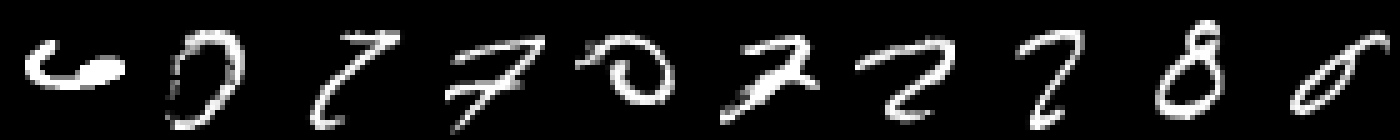

[6, 0, 7, 7, 0, 2, 2, 2, 8, 0]


In [22]:
trainer.show_worst_misclassified(net)

In [40]:
epochs = 20

net2 = Net(glorot_init=True)
gradient_visualizer = GradientVisualizer(net2, epochs)

FigureWidget({
    'data': [{'mode': 'lines+markers',
              'name': 'Linear layer 0',
              'type': 'scatter',
              'uid': 'f5cfbc3e-d6a4-4b85-848c-d9c186125afe',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 1',
              'type': 'scatter',
              'uid': '12a6d5df-fa37-4d07-95e7-fc091f331a6a',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 2',
              'type': 'scatter',
              'uid': '27adda6a-b8f4-4f16-b239-7850f1a7f5b5',
              'x': [],
              'y': []}],
    'layout': {'height': 400,
               'margin': {'b': 10, 't': 60},
               'template': '...',
               'title': {'text': 'Gradient stddev to weight stddev ratio', 'x': 0.5},
               'width': 1500,
               'xaxis': {'title': {'text': 'Epoch'}},
               'yaxis': {'title': {'text': 'G

FigureWidget({
    'data': [{'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.18)'},
              'mode': 'lines',
              'name': 'Epoch 1',
              'type': 'scatter',
              'uid': 'd3f4be33-048c-4525-9729-dc1d3e7a5ff3',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.27)'},
              'mode': 'lines',
              'name': 'Epoch 4',
              'type': 'scatter',
              'uid': 'a2d4a394-d400-4a2f-8321-c99b2b533fd2',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.36)'},
              'mode': 'lines',
              'name': 'Epoch 7',
              'type': 'scatter',
              'uid': '22ea93d6-ce39-4f82-9da7-e96762a4fdcc',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'

FigureWidget({
    'data': [{'line': {'color': 'rgb(99, 110, 250)'},
              'mode': 'lines',
              'name': 'Linear layer 0',
              'showlegend': True,
              'type': 'scatter',
              'uid': '4fcb0cba-b3bb-4aba-848a-940e0cd737c0',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(239, 85, 59)'},
              'mode': 'lines',
              'name': 'Linear layer 1',
              'showlegend': True,
              'type': 'scatter',
              'uid': '0c801c6b-1fa8-45ef-bd64-0d210d1666b4',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(0, 204, 150)'},
              'mode': 'lines',
              'name': 'Linear layer 2',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'd5c8572e-e5bd-4108-8f18-d704254c8b25',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(99, 110, 250)'},
   

In [41]:
trainer = MnistTrainer(batch_size=128)
trainer.train(net2, gradient_visualizer, epochs=epochs)

epoch     1, batch   100, loss 0.728
epoch     1, batch   200, loss 0.275
epoch     1, batch   300, loss 0.240
epoch     1, batch   400, loss 0.183
Accuracy of the network on the 10000 test images: 94.88%
epoch     2, batch   100, loss 0.155
epoch     2, batch   200, loss 0.147
epoch     2, batch   300, loss 0.132
epoch     2, batch   400, loss 0.128
Accuracy of the network on the 10000 test images: 95.92%
epoch     3, batch   100, loss 0.107
epoch     3, batch   200, loss 0.109
epoch     3, batch   300, loss 0.119
epoch     3, batch   400, loss 0.094
Accuracy of the network on the 10000 test images: 96.49%
epoch     4, batch   100, loss 0.073
epoch     4, batch   200, loss 0.088
epoch     4, batch   300, loss 0.093
epoch     4, batch   400, loss 0.078
Accuracy of the network on the 10000 test images: 97.17%
epoch     5, batch   100, loss 0.067
epoch     5, batch   200, loss 0.065
epoch     5, batch   300, loss 0.072
epoch     5, batch   400, loss 0.070
Accuracy of the network on the 1

Accuracy of the network on the 10000 test images: 97.46%


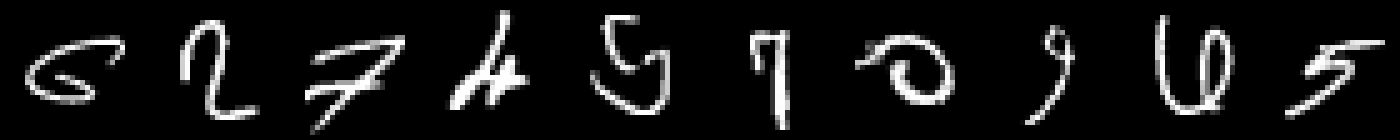

[6, 2, 7, 4, 5, 7, 0, 9, 6, 5]


In [42]:
trainer.show_worst_misclassified(net2)

In [43]:
#TASK 3

In [44]:

class Net3(nn.Module):
    def __init__(self, glorot_init: bool = False) -> None:
        super().__init__()
        self.fc1 = Linear(784, 64, glorot_init=glorot_init)
        self.fc2 = Linear(64, 64, glorot_init=glorot_init)
        self.fc3 = Linear(64, 64, glorot_init=glorot_init)
        self.fc4 = Linear(64, 64, glorot_init=glorot_init)
        self.fc5 = Linear(64, 64, glorot_init=glorot_init)
        self.fc6 = Linear(64, 64, glorot_init=glorot_init)
        self.fc7 = Linear(64, 64, glorot_init=glorot_init)
        self.fc8 = Linear(64, 10, glorot_init=glorot_init)



    def forward(self, x: Tensor) -> Tensor:
        """
        Input: shape (B, H=28, W=28)
        Output: shape (B, num_classes=10)
        """
        x = x.view(-1, 28 * 28)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = F.relu(self.fc4(x))
        x = F.relu(self.fc5(x))
        x = F.relu(self.fc6(x))
        x = F.relu(self.fc7(x))
        x = self.fc8(x)
        return x

In [45]:
epochs = 10

net3_uninit = Net3()
gradient_visualizer = GradientVisualizer(net3_uninit, epochs)

FigureWidget({
    'data': [{'mode': 'lines+markers',
              'name': 'Linear layer 0',
              'type': 'scatter',
              'uid': 'c34e621d-b98d-4920-832e-d78bd0f5e382',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 1',
              'type': 'scatter',
              'uid': '1a96e599-65a8-4f2c-8bb1-01c7355a4914',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 2',
              'type': 'scatter',
              'uid': '2e50751a-06ee-47cd-9bcf-4958c87cbd1e',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 3',
              'type': 'scatter',
              'uid': '5d271298-8572-4413-ace3-417f59e9a002',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 4',
              'type': 'sca

FigureWidget({
    'data': [{'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.21)'},
              'mode': 'lines',
              'name': 'Epoch 1',
              'type': 'scatter',
              'uid': '05312550-8d62-4900-b2d0-72dd6be3d7a3',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.27)'},
              'mode': 'lines',
              'name': 'Epoch 2',
              'type': 'scatter',
              'uid': '6d877e39-7f91-46ad-8627-05c40bfbe281',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.39)'},
              'mode': 'lines',
              'name': 'Epoch 4',
              'type': 'scatter',
              'uid': 'b8553b96-f7f7-4a11-ade8-733c607269db',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'

FigureWidget({
    'data': [{'line': {'color': 'rgb(99, 110, 250)'},
              'mode': 'lines',
              'name': 'Linear layer 0',
              'showlegend': True,
              'type': 'scatter',
              'uid': '140665b0-5c81-4e38-9b9b-8b849271eba5',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(239, 85, 59)'},
              'mode': 'lines',
              'name': 'Linear layer 1',
              'showlegend': True,
              'type': 'scatter',
              'uid': '8293fd68-301a-4b8c-9406-1ca5d3a14470',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(0, 204, 150)'},
              'mode': 'lines',
              'name': 'Linear layer 2',
              'showlegend': True,
              'type': 'scatter',
              'uid': '40753319-4699-45d4-9ace-4797c42219a3',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(171, 99, 250)'},
   

In [46]:
trainer.train(net3_uninit, gradient_visualizer, epochs=epochs)

epoch     1, batch   100, loss 3.679
epoch     1, batch   200, loss 2.302
epoch     1, batch   300, loss 2.298
epoch     1, batch   400, loss 2.241
Accuracy of the network on the 10000 test images: 11.35%
epoch     2, batch   100, loss 2.303
epoch     2, batch   200, loss 2.302
epoch     2, batch   300, loss 2.302
epoch     2, batch   400, loss 2.302
Accuracy of the network on the 10000 test images: 11.35%
epoch     3, batch   100, loss 2.303
epoch     3, batch   200, loss 2.301
epoch     3, batch   300, loss 2.301
epoch     3, batch   400, loss 2.302
Accuracy of the network on the 10000 test images: 11.35%
epoch     4, batch   100, loss 2.302
epoch     4, batch   200, loss 2.301
epoch     4, batch   300, loss 2.303
epoch     4, batch   400, loss 2.303
Accuracy of the network on the 10000 test images: 11.35%
epoch     5, batch   100, loss 2.302
epoch     5, batch   200, loss 2.302
epoch     5, batch   300, loss 2.303
epoch     5, batch   400, loss 2.302
Accuracy of the network on the 1

In [47]:
epochs = 10

net3_init = Net3(glorot_init=True)
gradient_visualizer = GradientVisualizer(net3_init, epochs)

FigureWidget({
    'data': [{'mode': 'lines+markers',
              'name': 'Linear layer 0',
              'type': 'scatter',
              'uid': 'a3b0fb3d-d72a-425f-a949-b91d887303c6',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 1',
              'type': 'scatter',
              'uid': '6b17ee55-fd08-42c3-99e2-0b6160594b4e',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 2',
              'type': 'scatter',
              'uid': '86e7c48c-8ca3-4ff7-94f7-b7fc25c1fc75',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 3',
              'type': 'scatter',
              'uid': 'c8803dc4-2009-4253-b05d-6a1f94059c3c',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 4',
              'type': 'sca

FigureWidget({
    'data': [{'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.21)'},
              'mode': 'lines',
              'name': 'Epoch 1',
              'type': 'scatter',
              'uid': '12815c0a-291d-4b33-823f-b800ce6c1135',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.27)'},
              'mode': 'lines',
              'name': 'Epoch 2',
              'type': 'scatter',
              'uid': '9a18cae6-71f6-464f-bdf6-af979ee4ea9f',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.39)'},
              'mode': 'lines',
              'name': 'Epoch 4',
              'type': 'scatter',
              'uid': '3efc28b7-3cc7-4638-9dd2-aa3c8f3bb539',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'

FigureWidget({
    'data': [{'line': {'color': 'rgb(99, 110, 250)'},
              'mode': 'lines',
              'name': 'Linear layer 0',
              'showlegend': True,
              'type': 'scatter',
              'uid': '70b5d438-7ed3-4f3b-8936-a53a7b828744',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(239, 85, 59)'},
              'mode': 'lines',
              'name': 'Linear layer 1',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'b2d5cf6b-abab-4747-9e6c-c1f5e11b3060',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(0, 204, 150)'},
              'mode': 'lines',
              'name': 'Linear layer 2',
              'showlegend': True,
              'type': 'scatter',
              'uid': '9f9b27f0-b442-41f6-8ba9-e636a8ff220f',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(171, 99, 250)'},
   

In [48]:
trainer.train(net3_init, gradient_visualizer, epochs=epochs)

epoch     1, batch   100, loss 1.447
epoch     1, batch   200, loss 0.406
epoch     1, batch   300, loss 0.283
epoch     1, batch   400, loss 0.243
Accuracy of the network on the 10000 test images: 94.42%
epoch     2, batch   100, loss 0.174
epoch     2, batch   200, loss 0.173
epoch     2, batch   300, loss 0.164
epoch     2, batch   400, loss 0.166
Accuracy of the network on the 10000 test images: 95.77%
epoch     3, batch   100, loss 0.132
epoch     3, batch   200, loss 0.138
epoch     3, batch   300, loss 0.129
epoch     3, batch   400, loss 0.117
Accuracy of the network on the 10000 test images: 96.34%
epoch     4, batch   100, loss 0.106
epoch     4, batch   200, loss 0.111
epoch     4, batch   300, loss 0.102
epoch     4, batch   400, loss 0.104
Accuracy of the network on the 10000 test images: 96.75%
epoch     5, batch   100, loss 0.091
epoch     5, batch   200, loss 0.080
epoch     5, batch   300, loss 0.086
epoch     5, batch   400, loss 0.087
Accuracy of the network on the 1

In [ ]:
#task4

In [53]:
class Dropout(nn.Module):
    def __init__(self, p: float = 0.25) -> None:
        super().__init__()
        assert 0 <= p <= 1
        self.p = p

    def forward(self, x: Tensor) -> Tensor:
      if not self.training or self.p == 0:
        return x
      mask = (torch.rand_like(x) >= self.p).float()
      return x * mask / (1.0 - self.p)


In [54]:
class NetN(nn.Module):
    def __init__(self, hidden_layers: int, glorot_init: bool = True, dropout: bool = True):
        super().__init__()
        layers = []
        in_f = 784
        for _ in range(hidden_layers):
            layers += [Linear(in_f, 64, glorot_init), nn.ReLU()]
            if dropout:
                layers.append(Dropout(0.25))
            in_f = 64
        layers.append(Linear(in_f, 10, glorot_init))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x.view(-1, 28 * 28))


In [61]:
epochs = 20

net4 = NetN(7)
gradient_visualizer = GradientVisualizer(net4, epochs)

FigureWidget({
    'data': [{'mode': 'lines+markers',
              'name': 'Linear layer 0',
              'type': 'scatter',
              'uid': 'b83308b3-1222-42b5-a55d-e6473a9e5e24',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 1',
              'type': 'scatter',
              'uid': '6cd1d745-da12-409b-9736-62d2f80b8b71',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 2',
              'type': 'scatter',
              'uid': '25e3f00b-2500-4912-a46e-0ad51c87e724',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 3',
              'type': 'scatter',
              'uid': '1508c510-7202-4894-9994-93d5c99bdccf',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 4',
              'type': 'sca

FigureWidget({
    'data': [{'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.18)'},
              'mode': 'lines',
              'name': 'Epoch 1',
              'type': 'scatter',
              'uid': '1749bd08-f2d2-46a3-b716-ddba672e0826',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.27)'},
              'mode': 'lines',
              'name': 'Epoch 4',
              'type': 'scatter',
              'uid': '8d9e0187-7685-4886-9222-792309361b77',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.36)'},
              'mode': 'lines',
              'name': 'Epoch 7',
              'type': 'scatter',
              'uid': 'a977a1d3-f924-41d0-a1c6-868893b3a696',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'

FigureWidget({
    'data': [{'line': {'color': 'rgb(99, 110, 250)'},
              'mode': 'lines',
              'name': 'Linear layer 0',
              'showlegend': True,
              'type': 'scatter',
              'uid': '4f8b784a-b790-400b-9043-c71690c5028e',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(239, 85, 59)'},
              'mode': 'lines',
              'name': 'Linear layer 1',
              'showlegend': True,
              'type': 'scatter',
              'uid': '01c8e873-3349-44d3-871c-12dfa2e9db2e',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(0, 204, 150)'},
              'mode': 'lines',
              'name': 'Linear layer 2',
              'showlegend': True,
              'type': 'scatter',
              'uid': '366891f0-5560-4596-acb1-388bedf305bb',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(171, 99, 250)'},
   

In [62]:
trainer.train(net4, gradient_visualizer, epochs=epochs)

epoch     1, batch   100, loss 2.014
epoch     1, batch   200, loss 1.300
epoch     1, batch   300, loss 1.010
epoch     1, batch   400, loss 0.858
Accuracy of the network on the 10000 test images: 83.42%
epoch     2, batch   100, loss 0.712
epoch     2, batch   200, loss 0.677
epoch     2, batch   300, loss 0.632
epoch     2, batch   400, loss 0.588
Accuracy of the network on the 10000 test images: 91.67%
epoch     3, batch   100, loss 0.524
epoch     3, batch   200, loss 0.498
epoch     3, batch   300, loss 0.530
epoch     3, batch   400, loss 0.509
Accuracy of the network on the 10000 test images: 92.99%
epoch     4, batch   100, loss 0.488
epoch     4, batch   200, loss 0.432
epoch     4, batch   300, loss 0.448
epoch     4, batch   400, loss 0.439
Accuracy of the network on the 10000 test images: 93.61%
epoch     5, batch   100, loss 0.432
epoch     5, batch   200, loss 0.439
epoch     5, batch   300, loss 0.420
epoch     5, batch   400, loss 0.419
Accuracy of the network on the 1

In [63]:
#task5

In [64]:
net10_u = NetN(10, dropout=False)
gradient_visualizer = GradientVisualizer(net10_u, epochs)

FigureWidget({
    'data': [{'mode': 'lines+markers',
              'name': 'Linear layer 0',
              'type': 'scatter',
              'uid': 'a37071fc-a889-41d3-a270-fff468fe7684',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 1',
              'type': 'scatter',
              'uid': '399c1bcb-f49a-45ed-997c-414a34c39bb9',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 2',
              'type': 'scatter',
              'uid': 'c96b32f5-af96-4c60-bfb0-615272c5f3a5',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 3',
              'type': 'scatter',
              'uid': '7372c4e1-b3b3-40f9-9ba9-dffad6932c9e',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 4',
              'type': 'sca

FigureWidget({
    'data': [{'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.18)'},
              'mode': 'lines',
              'name': 'Epoch 1',
              'type': 'scatter',
              'uid': '2d23a10c-67c2-4c63-a209-30541050f34b',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.27)'},
              'mode': 'lines',
              'name': 'Epoch 4',
              'type': 'scatter',
              'uid': '698f1994-2a95-47c5-9ced-df36e154c64c',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.36)'},
              'mode': 'lines',
              'name': 'Epoch 7',
              'type': 'scatter',
              'uid': 'afb089cf-08f8-4645-8121-775ebe43db7b',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'

FigureWidget({
    'data': [{'line': {'color': 'rgb(99, 110, 250)'},
              'mode': 'lines',
              'name': 'Linear layer 0',
              'showlegend': True,
              'type': 'scatter',
              'uid': '7564f31c-c545-42f0-93c1-b004d4684cec',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(239, 85, 59)'},
              'mode': 'lines',
              'name': 'Linear layer 1',
              'showlegend': True,
              'type': 'scatter',
              'uid': '32600dff-c253-4965-8acc-500c98f5aef5',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(0, 204, 150)'},
              'mode': 'lines',
              'name': 'Linear layer 2',
              'showlegend': True,
              'type': 'scatter',
              'uid': '7e7d22a5-0dd3-43dc-bf28-3e2003d58ac6',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(171, 99, 250)'},
   

In [65]:
trainer.train(net10_u, gradient_visualizer, epochs=epochs)

epoch     1, batch   100, loss 1.654
epoch     1, batch   200, loss 0.653
epoch     1, batch   300, loss 0.391
epoch     1, batch   400, loss 0.316
Accuracy of the network on the 10000 test images: 92.57%
epoch     2, batch   100, loss 0.243
epoch     2, batch   200, loss 0.227
epoch     2, batch   300, loss 0.194
epoch     2, batch   400, loss 0.198
Accuracy of the network on the 10000 test images: 95.14%
epoch     3, batch   100, loss 0.169
epoch     3, batch   200, loss 0.166
epoch     3, batch   300, loss 0.149
epoch     3, batch   400, loss 0.144
Accuracy of the network on the 10000 test images: 96.16%
epoch     4, batch   100, loss 0.121
epoch     4, batch   200, loss 0.124
epoch     4, batch   300, loss 0.126
epoch     4, batch   400, loss 0.131
Accuracy of the network on the 10000 test images: 96.46%
epoch     5, batch   100, loss 0.098
epoch     5, batch   200, loss 0.111
epoch     5, batch   300, loss 0.097
epoch     5, batch   400, loss 0.122
Accuracy of the network on the 1

In [66]:
net10_i = NetN(10, dropout=True)
gradient_visualizer = GradientVisualizer(net10_i, epochs)

FigureWidget({
    'data': [{'mode': 'lines+markers',
              'name': 'Linear layer 0',
              'type': 'scatter',
              'uid': '5ea2d2db-3d71-4dff-8dad-880ff02cc22d',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 1',
              'type': 'scatter',
              'uid': 'aee6f5ac-9625-4d68-ab3a-4748e8cc0c96',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 2',
              'type': 'scatter',
              'uid': '35d608d5-052e-49ab-a495-e22a9f095c50',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 3',
              'type': 'scatter',
              'uid': '58d40103-5727-429d-b1fc-44030a7a50ef',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 4',
              'type': 'sca

FigureWidget({
    'data': [{'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.18)'},
              'mode': 'lines',
              'name': 'Epoch 1',
              'type': 'scatter',
              'uid': 'ccbf7319-d4cb-4e2e-9e0a-8b976dd11221',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.27)'},
              'mode': 'lines',
              'name': 'Epoch 4',
              'type': 'scatter',
              'uid': '2baa21d4-97fd-4c34-9ff3-c968377e97b9',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.36)'},
              'mode': 'lines',
              'name': 'Epoch 7',
              'type': 'scatter',
              'uid': 'cc2d3387-34f1-47a0-8c6b-fb785b098ef6',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'

FigureWidget({
    'data': [{'line': {'color': 'rgb(99, 110, 250)'},
              'mode': 'lines',
              'name': 'Linear layer 0',
              'showlegend': True,
              'type': 'scatter',
              'uid': '374a301d-0e95-48bb-aae9-f14f67c66d76',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(239, 85, 59)'},
              'mode': 'lines',
              'name': 'Linear layer 1',
              'showlegend': True,
              'type': 'scatter',
              'uid': '75accf31-7a3f-408d-9eeb-d124f30d4564',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(0, 204, 150)'},
              'mode': 'lines',
              'name': 'Linear layer 2',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'c9b7cbc2-02ba-48d8-b5bd-64302df4bde1',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(171, 99, 250)'},
   

In [67]:
trainer.train(net10_i, gradient_visualizer, epochs=epochs)

epoch     1, batch   100, loss 2.138
epoch     1, batch   200, loss 1.695
epoch     1, batch   300, loss 1.507
epoch     1, batch   400, loss 1.413
Accuracy of the network on the 10000 test images: 44.09%
epoch     2, batch   100, loss 1.345
epoch     2, batch   200, loss 1.330
epoch     2, batch   300, loss 1.314
epoch     2, batch   400, loss 1.279
Accuracy of the network on the 10000 test images: 50.06%
epoch     3, batch   100, loss 1.288
epoch     3, batch   200, loss 1.258
epoch     3, batch   300, loss 1.210
epoch     3, batch   400, loss 1.199
Accuracy of the network on the 10000 test images: 56.53%
epoch     4, batch   100, loss 1.172
epoch     4, batch   200, loss 1.193
epoch     4, batch   300, loss 1.137
epoch     4, batch   400, loss 1.071
Accuracy of the network on the 10000 test images: 70.03%
epoch     5, batch   100, loss 1.097
epoch     5, batch   200, loss 1.065
epoch     5, batch   300, loss 0.991
epoch     5, batch   400, loss 1.014
Accuracy of the network on the 1

In [68]:
#task6

In [69]:
class BatchNormal(nn.Module):
    def __init__(self, num_features: int, eps: float = 1e-5, momentum: float = 0.1) -> None:
        super().__init__()
        self.eps = eps
        self.momentum = momentum
        self.gamma = nn.Parameter(torch.ones(num_features))
        self.beta = nn.Parameter(torch.zeros(num_features))

        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))

    def forward(self, x: Tensor) -> Tensor:
        if self.training:
            mean = x.mean(dim=0)
            var = x.var(dim=0, unbiased=False)
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * mean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * var
        else:
            mean = self.running_mean
            var = self.running_var

        x_hat = (x - mean) / torch.sqrt(var + self.eps)
        return x_hat * self.gamma + self.beta

In [71]:
class NetNB(nn.Module):
    def __init__(self, hidden_layers, glorot_init=True, dropout=True, batchnorm=False):
        super().__init__()
        layers, in_f = [], 784
        for _ in range(hidden_layers):
            layers.append(Linear(in_f, 64, glorot_init))
            if batchnorm:
                layers.append(BatchNormal(64))
            layers.append(nn.ReLU())
            if dropout:
                layers.append(Dropout(0.25))
            in_f = 64
        layers.append(Linear(in_f, 10, glorot_init))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x.view(-1, 28 * 28))

epochs = 10
net10_bn = NetNB(10, dropout=False, batchnorm=True)
gv = GradientVisualizer(net10_bn, epochs)
trainer.train(net10_bn, gv, epochs=epochs)


FigureWidget({
    'data': [{'mode': 'lines+markers',
              'name': 'Linear layer 0',
              'type': 'scatter',
              'uid': '7709e0ac-51dc-4a64-ab62-da602915982f',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 1',
              'type': 'scatter',
              'uid': '6fc31404-90f4-4379-8d59-cce0d7f09370',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 2',
              'type': 'scatter',
              'uid': 'fb5aa3f5-d109-46d0-b913-a8d2db76027a',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 3',
              'type': 'scatter',
              'uid': 'b0f73451-654a-4f54-a7f2-c559a91787c7',
              'x': [],
              'y': []},
             {'mode': 'lines+markers',
              'name': 'Linear layer 4',
              'type': 'sca

FigureWidget({
    'data': [{'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.21)'},
              'mode': 'lines',
              'name': 'Epoch 1',
              'type': 'scatter',
              'uid': '4417606e-7708-4e53-b0aa-4b9bac912d30',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.27)'},
              'mode': 'lines',
              'name': 'Epoch 2',
              'type': 'scatter',
              'uid': 'feba91c0-2412-4b09-9402-1a71ace28e3c',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'color': 'rgba(99, 110, 250,0.39)'},
              'mode': 'lines',
              'name': 'Epoch 4',
              'type': 'scatter',
              'uid': 'e26ae02a-c577-4433-931a-f10875c828db',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'legendgroup': '0',
              'line': {'

FigureWidget({
    'data': [{'line': {'color': 'rgb(99, 110, 250)'},
              'mode': 'lines',
              'name': 'Linear layer 0',
              'showlegend': True,
              'type': 'scatter',
              'uid': '0be5596e-c405-4038-851e-0899d0ac16bd',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(239, 85, 59)'},
              'mode': 'lines',
              'name': 'Linear layer 1',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'ca8c2640-15ef-4ddd-8bac-b98ea765f017',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(0, 204, 150)'},
              'mode': 'lines',
              'name': 'Linear layer 2',
              'showlegend': True,
              'type': 'scatter',
              'uid': 'cab90df7-597d-448a-a24e-51b58fb13879',
              'xaxis': 'x',
              'yaxis': 'y'},
             {'line': {'color': 'rgb(171, 99, 250)'},
   

epoch     1, batch   100, loss 0.757
epoch     1, batch   200, loss 0.321
epoch     1, batch   300, loss 0.268
epoch     1, batch   400, loss 0.231
Accuracy of the network on the 10000 test images: 95.12%
epoch     2, batch   100, loss 0.183
epoch     2, batch   200, loss 0.175
epoch     2, batch   300, loss 0.158
epoch     2, batch   400, loss 0.154
Accuracy of the network on the 10000 test images: 95.94%
epoch     3, batch   100, loss 0.128
epoch     3, batch   200, loss 0.134
epoch     3, batch   300, loss 0.121
epoch     3, batch   400, loss 0.114
Accuracy of the network on the 10000 test images: 96.81%
epoch     4, batch   100, loss 0.108
epoch     4, batch   200, loss 0.111
epoch     4, batch   300, loss 0.096
epoch     4, batch   400, loss 0.106
Accuracy of the network on the 10000 test images: 97.14%
epoch     5, batch   100, loss 0.082
epoch     5, batch   200, loss 0.086
epoch     5, batch   300, loss 0.088
epoch     5, batch   400, loss 0.099
Accuracy of the network on the 1

In [ ]:
#task7


Design and implement a simple convolutional network and achieve 99% test accuracy (in up to 10 epochs, 5 should be enough). The architecture is up to you, but even a few convolutional layers should be enough. You may use torch.nn.Conv2d, BatchNorm2d, MaxPool2d, ReLU, Dropout2d, Linear, Flatten, BatchNorm1d. Don't make it too generic, just try a few fixed layers.





In [72]:
class ConvNet(nn.Module):
    def __init__(self, dropout: float = 0.25) -> None:
        super().__init__()
        # 1x28x28 -> 32x14x14
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        # 32x14x14 -> 64x7x7
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.pool = nn.MaxPool2d(2)
        self.drop2d = nn.Dropout2d(dropout)
        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.bn3 = nn.BatchNorm1d(128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x: Tensor) -> Tensor:
        """
        Input: shape (B, 1, 28, 28)
        Output: shape (B, 10)
        """
        x = self.pool(F.relu(self.bn1(self.conv1(x))))   # (B, 32, 14, 14)
        x = self.pool(F.relu(self.bn2(self.conv2(x))))   # (B, 64, 7, 7)
        x = self.drop2d(x)
        x = self.flatten(x)                              # (B, 3136)
        x = F.relu(self.bn3(self.fc1(x)))                # (B, 128)
        x = self.fc2(x)                                  # (B, 10)
        return x


In [74]:
epochs = 10
conv_net = ConvNet()
trainer = MnistTrainer(batch_size=128)
trainer.train(conv_net, None, epochs=epochs)


epoch     1, batch   100, loss 0.275
epoch     1, batch   200, loss 0.095
epoch     1, batch   300, loss 0.078
epoch     1, batch   400, loss 0.070
Accuracy of the network on the 10000 test images: 98.70%
epoch     2, batch   100, loss 0.049
epoch     2, batch   200, loss 0.047
epoch     2, batch   300, loss 0.041
epoch     2, batch   400, loss 0.043
Accuracy of the network on the 10000 test images: 99.07%
epoch     3, batch   100, loss 0.034
epoch     3, batch   200, loss 0.033
epoch     3, batch   300, loss 0.034
epoch     3, batch   400, loss 0.030
Accuracy of the network on the 10000 test images: 99.16%
epoch     4, batch   100, loss 0.026
epoch     4, batch   200, loss 0.024
epoch     4, batch   300, loss 0.026
epoch     4, batch   400, loss 0.026
Accuracy of the network on the 10000 test images: 99.14%
epoch     5, batch   100, loss 0.015
epoch     5, batch   200, loss 0.019
epoch     5, batch   300, loss 0.021
epoch     5, batch   400, loss 0.021
Accuracy of the network on the 1